In [ ]:
import os
from google.colab import drive
drive.mount("/content/drive")

if not os.path.exists("/content/fruitnet/archive (3)"):
  !unzip -n -q "/content/drive/MyDrive/fruitnet.zip" -d /content/fruitnet
if not os.path.exists("/content/data/train"):
  !rm -rf /content/data
  !python "/content/fruitnet/archive (3)/01_limpieza_y_division.py" --origen "/content/fruitnet/archive (3)" --salida /content/data
else:
  print("Carpetas train/val/test listas")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Carpetas train/val/test listas


In [ ]:
import os,json, time, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix, f1_score

In [ ]:
DATA = "/content/data"
RESULTADOS = "/content/drive/MyDrive/fruit_resultados"
os.makedirs(RESULTADOS, exist_ok = True)
PESOS_IMAGENET = "imagenet"

SEMILLA = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
keras.utils.set_random_seed(SEMILLA)

print("Tensorflow: ", tf.__version__)
print("GPU: ",tf.config.list_physical_devices("GPU") or "No hay GPU")

Tensorflow:  2.21.0
GPU:  [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
def cargar(split, shuffle):
  return keras.utils.image_dataset_from_directory(os.path.join(DATA, split), image_size=IMG_SIZE, batch_size= BATCH_SIZE, label_mode="categorical", shuffle=shuffle, seed=SEMILLA)

train_ds = cargar("train", True)
val_ds = cargar("val", False)

class_name = train_ds.class_names
NUM_CLASES = len(class_name)

y_val = np.concatenate([np.argmax(y, axis =1) for _, y in val_ds])
splits = pd.read_csv(os.path.join(DATA, "splits.csv"))
splits["anio"] = 0
con_fecha = splits["timestamp"] < 1e12
splits.loc[con_fecha, "anio"] = pd.to_datetime(splits.loc[con_fecha, "timestamp"], unit="s").dt.year

anio = dict(zip(splits["clase"] + "/" + splits["archivo"], splits["anio"]))
claves_val = [os.path.basename(os.path.dirname(p)) + "/" + os.path.basename(p) for p in val_ds.file_paths]
es_2020 = np.array([anio.get(k) == 2020 for k in claves_val])

print(f"Validacion: {len(y_val)} imagenes, {es_2020.sum()} del subconjunto 2020")

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)


Found 9592 files belonging to 12 classes.
Found 2055 files belonging to 12 classes.
Validacion: 2055 imagenes, 359 del subconjunto 2020


In [ ]:
fruta = lambda k: class_name[k].split("_")[0]
calidad = lambda k: class_name[k].split("_")[1]

def graficar_curvas(h, titulo):
  ep = range(1, len(h["loss"]) + 1)
  fig, axes = plt.subplots(1,2, figsize=(13,4.2))
  axes[0].plot(ep, h["loss"], "o-", label="Entrenamiento")
  axes[0].plot(ep, h["val_loss"], "o-", label="Validacion")
  axes[0].set_title("Funcion de costo"); axes[0].set_xlabel("Epochs")

  axes[1].plot(ep, h["accuracy"], "o-", label="Entrenamiento")
  axes[1].plot(ep, h["val_accuracy"], "o-", label="Validacion")
  axes[1].set_title("Exactitud"); axes[1].set_xlabel("Epochs")

  for ax in axes:
    ax.legend(); ax.grid(alpha = 0.3)
  plt.suptitle(titulo); plt.show()

In [ ]:
def evaluar(clave, nombre, modelo, h=None, minutos = 0.0, guardar_modelo = True):
  val_loss, val_acc = modelo.evaluate(val_ds, verbose =0)
  y_pred = np.argmax(modelo.predict(val_ds, verbose=0), axis=1)
  mal = y_val != y_pred
  err_fruta = np.array([fruta(a)!=fruta(b) for a, b in zip(y_val, y_pred)])
  conserva = sum(calidad(a) == calidad(b) for a, b in zip(y_val[err_fruta], y_pred[err_fruta]))
  acc_2020 = float((y_val[es_2020] == y_pred[es_2020]).mean())

  if h:
    mejor = int(np.argmin(h["val_loss"]))
    train_acc = float(h["accuracy"][mejor] if "restaura" in h else h["accuracy"][-1])
  else:
    train_acc = None

  r = {
      "clave": clave, "modelo": nombre,
      "parametros": int(modelo.count_params()),
      "parametros_entrenables": int(sum(np.prod(w.shape) for w in modelo.trainable_weights)),
      "epochs": len(h["loss"]) if h else None,
      "minutos": round(minutos, 1),
      "train_acc": round(train_acc, 4) if train_acc is not None else None,
      "val_acc": round(float(val_acc), 4),
      "val_loss": round(float(val_loss), 4),
      "f1_score": round(float(f1_score(y_val, y_pred, average="macro")), 4),
      "errores": int(mal.sum()),
      "errores_fruta": int(err_fruta.sum()),
      "errores_druta_conservan_calidad": int(conserva),
      "acc_2020": round(acc_2020, 4),
      "historial": {k: [round(float(v), 4) for v in vals] for k, vals in h.items() if k != "restaura"} if h else None,
  }

  with open(os.path.join(RESULTADOS, f"resultado_{clave}.json"), "w") as f:
    json.dump(r, f, indent=2, ensure_ascii=False)
  if guardar_modelo:
    modelo.save(os.path.join(RESULTADOS, f"modelo_{clave}.keras"))

  print(f"\n ==={nombre} ===")
  if train_acc is not None:
    print(f"Exactitud de entrenamiento: {train_acc:.3f} | validacion: {val_acc:.3f} | brecha: {train_acc - val_acc:.3f}")
  else:
    print(f"Exactitud de validacion: {val_acc:.3f}")
  print(f"Perdida de validacion: {val_loss:.3f} | F1 score: {r["f1_score"]:.3f}")
  print(f"Errores: {mal.sum()} | de fruta: {err_fruta.sum()}, ({conserva} de ellos conservan la calidad) | solo de calidad: {mal.sum() - err_fruta.sum()}")
  print(f"Exactitud en subconjunto 2020: {acc_2020:.3f}")
  return r, y_pred


In [ ]:
def entrenar(clave, nombre, modelo, epochs, lr, early_stopping=False, paciencia=5):
  modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=lr), loss = "categorical_crossentropy", metrics=["accuracy"])

  cb= []
  if early_stopping:
    cb.append(keras.callbacks.EarlyStopping(monitor="val_loss", patience=paciencia, restore_best_weights=True, verbose=1))
  inicio = time.time()
  hist = modelo.fit(train_ds, validation_data=val_ds, epochs = epochs, callbacks=cb)
  minutos =(time.time() - inicio) / 60
  h = dict(hist.history)
  if early_stopping:
    h["restaura"] = True
    print(f"Mejor epoch: {int (np.argmin(h['val_loss'])) +1} de {len(h['loss'])}")
  print(f"Tiempo de entrenamiento: {minutos:.1f} min")
  graficar_curvas(h, nombre)
  return evaluar(clave, nombre, modelo, h, minutos)


In [ ]:
modelo_base = keras.models.load_model(os.path.join(RESULTADOS, "modelo_base.keras"))
with open(os.path.join(RESULTADOS, "resultado_modelo_base.json")) as f:
  base_json = json.load(f)
r0, _ = evaluar("E0_base", "E0 x Modelo Base", modelo_base, guardar_modelo=False)
r0["train_acc"] = base_json["train_acc"]
r0["epochs"] = base_json.get("epochs", base_json.get("epochs"))
r0["minutos"] = base_json["minutos"]
with open(os.path.join(RESULTADOS, "resultado_E0_base.json"), "w") as f:
  json.dump(r0, f, indent=2, ensure_ascii=False)


 ===E0 x Modelo Base ===
Exactitud de validacion: 0.605
Perdida de validacion: 3.754 | F1 score: 0.603
Errores: 811 | de fruta: 610, (437 de ellos conservan la calidad) | solo de calidad: 201
Exactitud en subconjunto 2020: 0.251


In [ ]:
def bloques_conv(x, batch_norm=False):
  for filtros in [32, 64, 128]:
    x = layers.Conv2D(filtros, 3, padding="same", use_bias=not batch_norm)(x)
    if batch_norm:
      x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D()(x)
  return x


Model: "E1_gap"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_12 (InputLayer)     │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_8 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_18 (Activation)      │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_18 (MaxPooling2D) │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_19 (Activation)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_19 (MaxPooling2D) │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_20 (Conv2D)              │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_20 (Activation)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_20 (MaxPooling2D) │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_6      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 12)             │         1,548 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,308 (434.80 KB)

 Trainable params: 111,308 (434.80 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 24s 70ms/step - accuracy: 0.4097 - loss: 1.6968 - val_accuracy: 0.4647 - val_loss: 1.6584
Epoch 2/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 18s 60ms/step - accuracy: 0.6504 - loss: 0.9613 - val_accuracy: 0.5557 - val_loss: 1.5642
Epoch 3/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 19s 62ms/step - accuracy: 0.7447 - loss: 0.7392 - val_accuracy: 0.5903 - val_loss: 1.4214
Epoch 4/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 18s 59ms/step - accuracy: 0.8040 - loss: 0.5893 - val_accuracy: 0.6516 - val_loss: 1.3167
Epoch 5/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 18s 60ms/step - accuracy: 0.8276 - loss: 0.5090 - val_accuracy: 0.6336 - val_loss: 1.4500
Epoch 6/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 18s 60ms/step - accuracy: 0.8555 - loss: 0.4368 - val_accuracy: 0.5854 - val_loss: 1.6421
Epoch 7/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 21s 60ms/step - accuracy: 0.8625 - loss: 0.4088 - val_accuracy: 0.7022 - val_loss: 1.5171
Epoch 8/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 18s 60ms/step - accuracy: 0.8824 - loss: 0.3589 - 

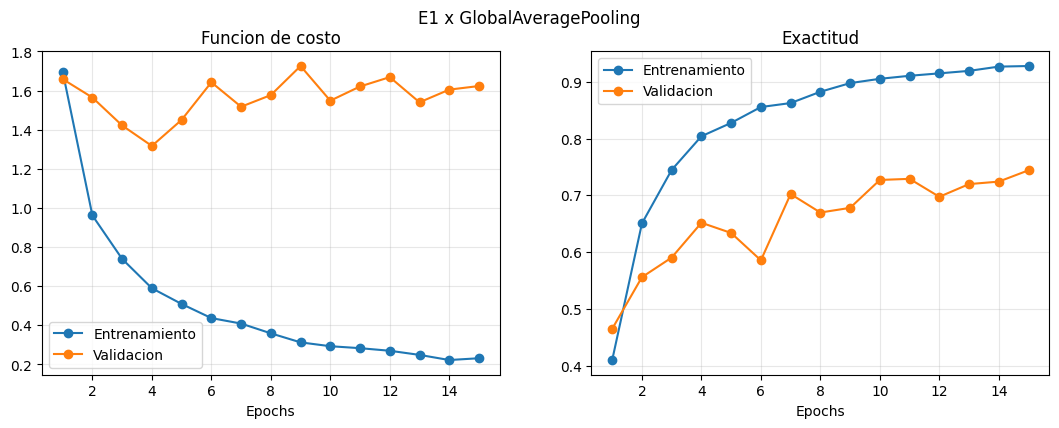


 ===E1 x GlobalAveragePooling ===
Exactitud de entrenamiento: 0.928 | validacion: 0.744 | brecha: 0.184
Perdida de validacion: 1.623 | F1 score: 0.747
Errores: 526 | de fruta: 432, (286 de ellos conservan la calidad) | solo de calidad: 94
Exactitud en subconjunto 2020: 0.323


In [ ]:
def crear_e1():
  entrada = keras.Input(shape=IMG_SIZE +(3,))
  x = layers.Rescaling(1.0 / 225)(entrada)
  x = bloques_conv(x)
  x = layers.GlobalAveragePooling2D()(x)
  x = layers.Dense(128, activation="relu")(x)
  salida = layers.Dense(NUM_CLASES, activation="softmax")(x)
  return keras.Model(entrada, salida, name="E1_gap")

keras.utils.set_random_seed(SEMILLA)
m1 = crear_e1()
m1.summary()
r1, _ = entrenar("e1_gap", "E1 x GlobalAveragePooling", m1, epochs = 15, lr=1e-3)

Epoch 1/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 30s 83ms/step - accuracy: 0.5928 - loss: 1.2911 - val_accuracy: 0.1032 - val_loss: 3.4120
Epoch 2/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 21s 69ms/step - accuracy: 0.7557 - loss: 0.7707 - val_accuracy: 0.3723 - val_loss: 2.0107
Epoch 3/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 21s 69ms/step - accuracy: 0.8096 - loss: 0.6133 - val_accuracy: 0.4501 - val_loss: 2.0003
Epoch 4/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 41s 68ms/step - accuracy: 0.8314 - loss: 0.5346 - val_accuracy: 0.2715 - val_loss: 5.6696
Epoch 5/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 41s 70ms/step - accuracy: 0.8614 - loss: 0.4423 - val_accuracy: 0.3601 - val_loss: 2.4820
Epoch 6/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 21s 69ms/step - accuracy: 0.8731 - loss: 0.4115 - val_accuracy: 0.5246 - val_loss: 2.0302
Epoch 7/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 41s 68ms/step - accuracy: 0.8796 - loss: 0.3739 - val_accuracy: 0.6511 - val_loss: 1.3495
Epoch 8/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 41s 69ms/step - accuracy: 0.8924 - loss: 0.3445 - 

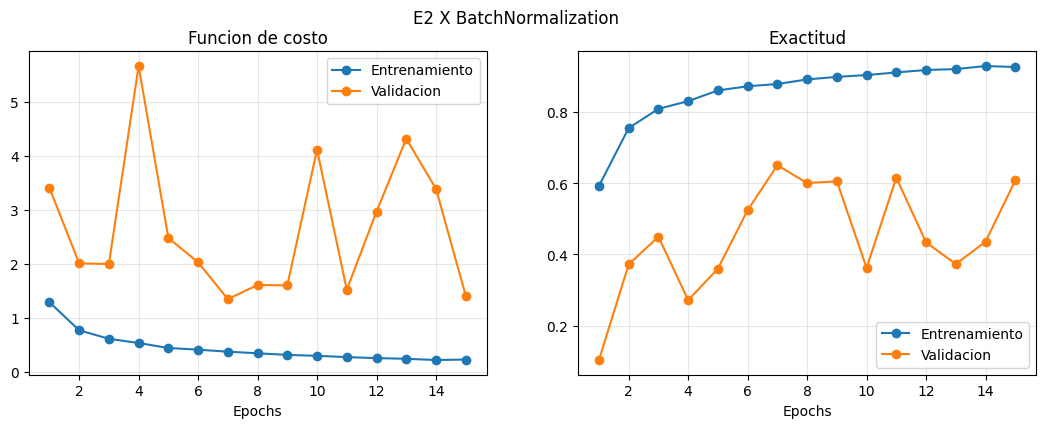


 ===E2 X BatchNormalization ===
Exactitud de entrenamiento: 0.927 | validacion: 0.608 | brecha: 0.319
Perdida de validacion: 1.414 | F1 score: 0.618
Errores: 805 | de fruta: 631, (427 de ellos conservan la calidad) | solo de calidad: 174
Exactitud en subconjunto 2020: 0.242


In [ ]:
def crear_e2(aumento = None):
  entrada = keras.Input(shape = IMG_SIZE + (3,))
  x = aumento(entrada) if aumento is not None else entrada
  x = layers.Rescaling(1.0/ 255)(x)
  x = bloques_conv(x, batch_norm =True)
  x = layers.GlobalAveragePooling2D()(x)
  x = layers.Dense(128, activation="relu")(x)
  x = layers.Dropout(0.5)(x)
  salida = layers.Dense(NUM_CLASES, activation="softmax")(x)
  return keras.Model(entrada, salida, name="E2_bn_dropout" if aumento is None else "E3_Aumento")

keras.utils.set_random_seed(SEMILLA)
m2 = crear_e2()
r2, _ = entrenar("E2_bn_dropout", "E2 X BatchNormalization", m2, epochs = 15, lr=1e-3)

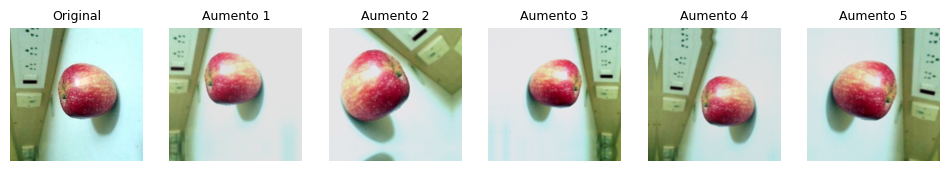

Epoch 1/40
300/300 ━━━━━━━━━━━━━━━━━━━━ 42s 130ms/step - accuracy: 0.5202 - loss: 1.5001 - val_accuracy: 0.0847 - val_loss: 3.0512
Epoch 2/40
300/300 ━━━━━━━━━━━━━━━━━━━━ 38s 127ms/step - accuracy: 0.6686 - loss: 1.0199 - val_accuracy: 0.4856 - val_loss: 1.5956
Epoch 3/40
300/300 ━━━━━━━━━━━━━━━━━━━━ 38s 126ms/step - accuracy: 0.7180 - loss: 0.8717 - val_accuracy: 0.3426 - val_loss: 2.2862
Epoch 4/40
300/300 ━━━━━━━━━━━━━━━━━━━━ 38s 127ms/step - accuracy: 0.7452 - loss: 0.7717 - val_accuracy: 0.1985 - val_loss: 4.4035
Epoch 5/40
300/300 ━━━━━━━━━━━━━━━━━━━━ 38s 127ms/step - accuracy: 0.7774 - loss: 0.6866 - val_accuracy: 0.4428 - val_loss: 2.3576
Epoch 6/40
300/300 ━━━━━━━━━━━━━━━━━━━━ 38s 128ms/step - accuracy: 0.7825 - loss: 0.6499 - val_accuracy: 0.3932 - val_loss: 2.4577
Epoch 7/40
300/300 ━━━━━━━━━━━━━━━━━━━━ 38s 126ms/step - accuracy: 0.8059 - loss: 0.5900 - val_accuracy: 0.3601 - val_loss: 4.0274
Epoch 7: early stopping
Restoring model weights from the end of the best epoch: 2.


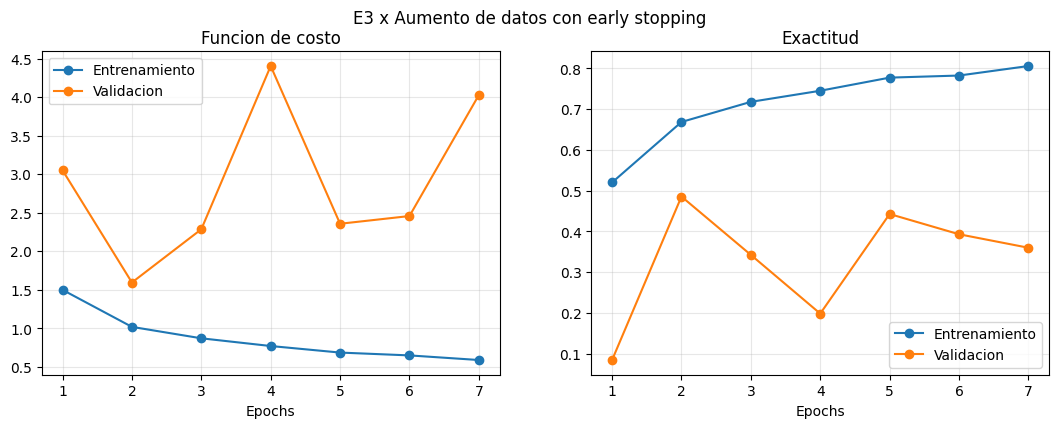


 ===E3 x Aumento de datos con early stopping ===
Exactitud de entrenamiento: 0.669 | validacion: 0.486 | brecha: 0.183
Perdida de validacion: 1.596 | F1 score: 0.475
Errores: 1057 | de fruta: 907, (695 de ellos conservan la calidad) | solo de calidad: 150
Exactitud en subconjunto 2020: 0.201


In [ ]:
aumento = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.2),
    layers.RandomTranslation(0.1,0.1),
    layers.RandomBrightness(0.2, value_range=(0,225)),
    layers.RandomContrast(0.2),
], name = "aumento_datos")


imgs, _ = next(iter(train_ds))
plt.figure(figsize=(12, 3))
for i in range(6):
  plt.subplot(1, 6, i +1)
  img = imgs[0] if i == 0 else aumento(imgs[:1], training=True)[0]
  plt.imshow(np.clip(np.asarray(img), 0, 255).astype("uint8")); plt.axis("off")
  plt.title("Original" if i == 0 else f"Aumento {i}", fontsize=9)
plt.show()

keras.utils.set_random_seed(SEMILLA)
m3 = crear_e2(aumento)
r3, _ = entrenar("E3_Aumento", "E3 x Aumento de datos con early stopping", m3, epochs = 40, lr=1e-3, early_stopping=True, paciencia=5)

Model: "E4_MobilenetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_17 (InputLayer)     │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aumento_datos (Sequential)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_11 (Rescaling)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_9      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 12)             │        15,372 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,273,356 (8.67 MB)

 Trainable params: 15,372 (60.05 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 28s 78ms/step - accuracy: 0.8264 - loss: 0.5788 - val_accuracy: 0.8404 - val_loss: 0.5075
Epoch 2/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 22s 73ms/step - accuracy: 0.9413 - loss: 0.2011 - val_accuracy: 0.8589 - val_loss: 0.5007
Epoch 3/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 22s 72ms/step - accuracy: 0.9582 - loss: 0.1431 - val_accuracy: 0.8599 - val_loss: 0.5057
Epoch 4/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 41s 73ms/step - accuracy: 0.9668 - loss: 0.1138 - val_accuracy: 0.8686 - val_loss: 0.5353
Epoch 5/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 22s 73ms/step - accuracy: 0.9684 - loss: 0.1023 - val_accuracy: 0.8813 - val_loss: 0.5113
Epoch 6/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 22s 72ms/step - accuracy: 0.9700 - loss: 0.0927 - val_accuracy: 0.8764 - val_loss: 0.5490
Epoch 7/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 23s 78ms/step - accuracy: 0.9741 - loss: 0.0852 - val_accuracy: 0.8715 - val_loss: 0.5261
Epoch 7: early stopping
Restoring model weights from the end of the best epoch: 2.
Mejor e

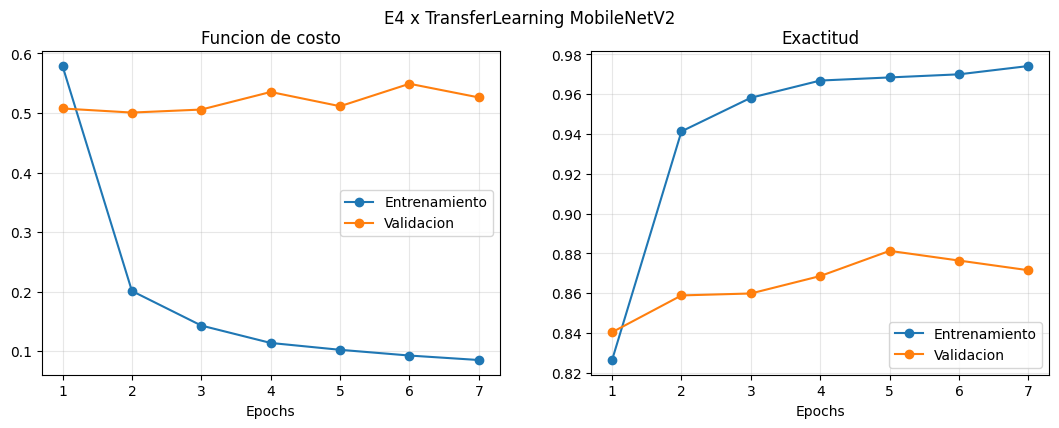


 ===E4 x TransferLearning MobileNetV2 ===
Exactitud de entrenamiento: 0.941 | validacion: 0.859 | brecha: 0.082
Perdida de validacion: 0.501 | F1 score: 0.859
Errores: 290 | de fruta: 222, (180 de ellos conservan la calidad) | solo de calidad: 68
Exactitud en subconjunto 2020: 0.518


In [ ]:
base_mnv2 = keras.applications.MobileNetV2(include_top=False, weights=PESOS_IMAGENET, input_shape=IMG_SIZE + (3,))
base_mnv2.trainable = False

def crear_e4():
  entrada = keras.Input(shape = IMG_SIZE + (3,))
  x = aumento(entrada)
  x = layers.Rescaling(1.0 / 127.5, offset=-1)(x)
  x = base_mnv2(x, training=False)
  x = layers.GlobalAveragePooling2D()(x)
  x = layers.Dropout(0.3)(x)
  salida = layers.Dense(NUM_CLASES, activation= "softmax")(x)
  return keras.Model(entrada, salida, name="E4_MobilenetV2")

keras.utils.set_random_seed(SEMILLA)
m4 = crear_e4()
m4.summary()
r4,_ = entrenar("E4_MobileNetV2", "E4 x TransferLearning MobileNetV2", m4, epochs=20, lr=1e-3, early_stopping=True, paciencia=5)

Epoch 1/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 74s 178ms/step - accuracy: 0.8472 - loss: 0.4994 - val_accuracy: 0.8482 - val_loss: 0.5141
Epoch 2/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 53s 178ms/step - accuracy: 0.9436 - loss: 0.1910 - val_accuracy: 0.8657 - val_loss: 0.4481
Epoch 3/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 52s 174ms/step - accuracy: 0.9624 - loss: 0.1248 - val_accuracy: 0.8925 - val_loss: 0.3987
Epoch 4/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 52s 173ms/step - accuracy: 0.9693 - loss: 0.1042 - val_accuracy: 0.8959 - val_loss: 0.3880
Epoch 5/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 51s 171ms/step - accuracy: 0.9804 - loss: 0.0721 - val_accuracy: 0.8954 - val_loss: 0.3801
Epoch 6/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 51s 171ms/step - accuracy: 0.9804 - loss: 0.0665 - val_accuracy: 0.8978 - val_loss: 0.3880
Epoch 7/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 52s 172ms/step - accuracy: 0.9850 - loss: 0.0569 - val_accuracy: 0.9051 - val_loss: 0.3649
Epoch 8/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 82s 172ms/step - accuracy: 0.9859 - loss: 0

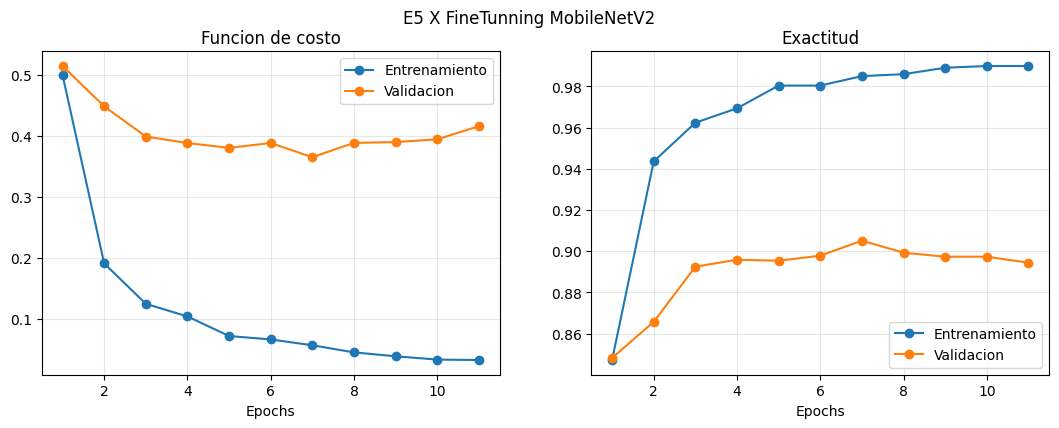


 ===E5 X FineTunning MobileNetV2 ===
Exactitud de entrenamiento: 0.985 | validacion: 0.905 | brecha: 0.080
Perdida de validacion: 0.365 | F1 score: 0.905
Errores: 195 | de fruta: 169, (108 de ellos conservan la calidad) | solo de calidad: 26
Exactitud en subconjunto 2020: 0.649


In [ ]:
base_mnv2.trainable = True
for capa in base_mnv2.layers[:30]:
  capa.trainable = False

m5 = m4
r5, y_pred_e5 = entrenar("E5_Finetunning", "E5 X FineTunning MobileNetV2", m5, epochs=15, lr=1e-5, early_stopping=True, paciencia=4)

In [ ]:
filas = []
for clave in ["E0_base", "e1_gap", "E2_bn_dropout", "E3_Aumento", "E4_MobileNetV2", "E5_Finetunning"]:
  ruta = os.path.join(RESULTADOS, f"resultado_{clave}.json")
  if os.path.exists(ruta):
    with open(ruta) as f:
      filas.append(json.load(f))

tabla = pd.DataFrame(filas).set_index("modelo")
tabla["brecha"] =tabla["train_acc"] - tabla["val_acc"]
tabla["% errores de fruta"] = (tabla["errores_fruta"] / tabla["errores"] * 100).round(1)
columnas = ["parametros", "parametros_entrenables", "epochs", "minutos", "train_acc", "val_acc","brecha", "val_loss", "f1_score", "% errores de fruta", "acc_2020"]
tabla[columnas].to_csv(os.path.join(RESULTADOS, "comparacion_experimentos.csv"))
tabla[columnas].round(3)

,parametros,parametros_entrenables,epochs,minutos,train_acc,val_acc,brecha,val_loss,f1_score,% errores de fruta,acc_2020
modelo,,,,,,,,,,,
E0 x Modelo Base,11170508,11170508,15,4.8,0.998,0.605,0.393,3.754,0.603,75.2,0.251
E1 x GlobalAveragePooling,111308,111308,15,4.7,0.928,0.744,0.184,1.623,0.747,82.1,0.323
E2 X BatchNormalization,111980,111532,15,7.7,0.927,0.608,0.319,1.414,0.618,78.4,0.242
E3 x Aumento de datos con early stopping,111980,111532,7,4.5,0.669,0.486,0.183,1.596,0.475,85.8,0.201
E4 x TransferLearning MobileNetV2,2273356,15372,7,3.0,0.941,0.859,0.082,0.501,0.859,76.6,0.518
E5 X FineTunning MobileNetV2,2273356,2219708,11,10.9,0.985,0.905,0.080,0.365,0.905,86.7,0.649


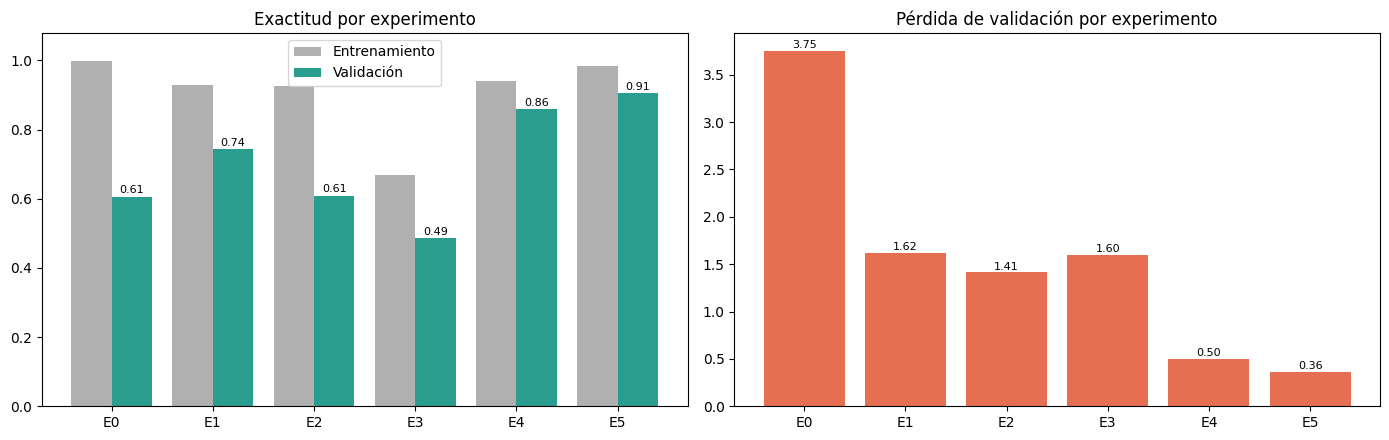

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
etiquetas = [f"E{i}" for i in range(len(tabla))]
x = np.arange(len(tabla))
axes[0].bar(x - 0.2, tabla["train_acc"], 0.4, label="Entrenamiento", color="#b0b0b0")
axes[0].bar(x + 0.2, tabla["val_acc"], 0.4, label="Validación", color="#2a9d8f")
for i, v in enumerate(tabla["val_acc"]):
    axes[0].text(i + 0.2, v + 0.01, f"{v:.2f}", ha="center", fontsize=8)
axes[0].set_xticks(x); axes[0].set_xticklabels(etiquetas)
axes[0].set_ylim(0, 1.08); axes[0].set_title("Exactitud por experimento"); axes[0].legend()

axes[1].bar(x, tabla["val_loss"], color="#e76f51")
for i, v in enumerate(tabla["val_loss"]):
    axes[1].text(i, v + 0.03, f"{v:.2f}", ha="center", fontsize=8)
axes[1].set_xticks(x); axes[1].set_xticklabels(etiquetas)
axes[1].set_title("Pérdida de validación por experimento")
plt.tight_layout(); plt.show()

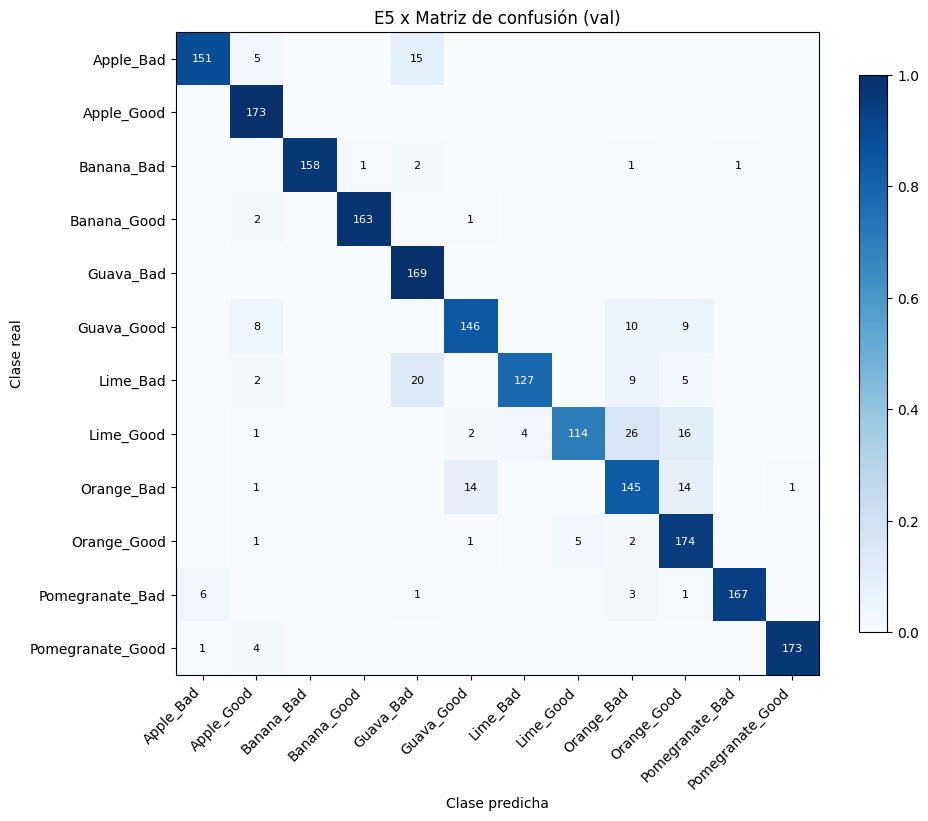

                  precision    recall  f1-score   support

       Apple_Bad      0.956     0.883     0.918       171
      Apple_Good      0.878     1.000     0.935       173
      Banana_Bad      1.000     0.969     0.984       163
     Banana_Good      0.994     0.982     0.988       166
       Guava_Bad      0.816     1.000     0.899       169
      Guava_Good      0.890     0.844     0.866       173
        Lime_Bad      0.969     0.779     0.864       163
       Lime_Good      0.958     0.699     0.809       163
      Orange_Bad      0.740     0.829     0.782       175
     Orange_Good      0.795     0.951     0.866       183
 Pomegranate_Bad      0.994     0.938     0.965       178
Pomegranate_Good      0.994     0.972     0.983       178

        accuracy                          0.905      2055
       macro avg      0.915     0.904     0.905      2055
    weighted avg      0.914     0.905     0.905      2055



In [ ]:
cm = confusion_matrix(y_val, y_pred_e5)
cm_norm = cm / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(NUM_CLASES)); ax.set_xticklabels(class_name, rotation=45, ha="right")
ax.set_yticks(range(NUM_CLASES)); ax.set_yticklabels(class_name)
for i in range(NUM_CLASES):
    for j in range(NUM_CLASES):
        if cm[i, j]:
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8,
                    color="white" if cm_norm[i, j] > 0.5 else "black")
ax.set_xlabel("Clase predicha"); ax.set_ylabel("Clase real")
ax.set_title("E5 x Matriz de confusión (val)")
plt.colorbar(im, ax=ax, shrink=0.8); plt.tight_layout(); plt.show()

print(classification_report(y_val, y_pred_e5, target_names=class_name, digits=3, zero_division=0))